# Лабораторная работа № 3
## DBSCAN


## Импорт библиотек


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection


## Подготовка данных


In [ ]:
# Загружаем таблицу и исключаем города с неполными данными.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab3/Econom_Cities_data.csv"
raw3 = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features3 = ['Work', 'Price', 'Salary']
cities3 = raw3.dropna(subset=features3).copy().reset_index(drop=True)
# Приводим три признака к одному масштабу.
X3 = StandardScaler().fit_transform(cities3[features3])
print('Исходно 48; исключены Cairo, Jakarta; в анализе:', len(cities3))


Исходно 48; исключены Cairo, Jakarta; в анализе: 46


In [ ]:
# Загружаем показатели стран за 1991 год и сопоставляем города со странами.
COUNTRIES_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/countries_1991.csv"
country_indicators = pd.read_csv(COUNTRIES_URL)
city_country = {
    'Amsterdam': 'Нидерланды',
    'Athens': 'Греция',
    'Bogota': 'Колумбия',
    'Bombay': 'Индия',
    'Brussels': 'Бельгия',
    'Buenos_Aires': 'Аргентина',
    'Cairo': 'Египет',
    'Caracas': 'Венесуэла',
    'Chicago': 'США',
    'Copenhagen': 'Дания',
    'Dublin': 'Ирландия',
    'Dusseldorf': 'Германия',
    'Frankfurt': 'Германия',
    'Geneva': 'Швейцария',
    'Helsinki': 'Финляндия',
    'Hong_Kong': 'Гонконг',
    'Houston': 'США',
    'Jakarta': 'Индонезия',
    'Johannesburg': 'ЮАР',
    'Kuala_Lumpur': 'Малайзия',
    'Lagos': 'Нигерия',
    'Lisbon': 'Португалия',
    'London': 'Великобритания',
    'Los_Angeles': 'США',
    'Luxembourg': 'Люксембург',
    'Madrid': 'Испания',
    'Manila': 'Филиппины',
    'Mexico_City': 'Мексика',
    'Milan': 'Италия',
    'Montreal': 'Канада',
    'Nairobi': 'Кения',
    'New_York': 'США',
    'Nicosia': 'Кипр',
    'Oslo': 'Норвегия',
    'Panama': 'Панама',
    'Paris': 'Франция',
    'Rio_de_Janeiro': 'Бразилия',
    'San_Paulo': 'Бразилия',
    'Seoul': 'Южная Корея',
    'Singpore': 'Сингапур',
    'Stockholm': 'Швеция',
    'Sydney': 'Австралия',
    'Taipei': 'Тайвань',
    'Tel_Aviv': 'Израиль',
    'Tokyo': 'Япония',
    'Toronto': 'Канада',
    'Vienna': 'Австрия',
    'Zurich': 'Швейцария',
}
external_features = ['HDI', 'Life_expectancy']


# Присоединяем национальные показатели к городам.
def attach_country_indicators(city_data):
    external = city_data[['City']].copy()
    external['Country'] = external.City.map(city_country)
    return external.merge(country_indicators, on='Country', how='left',
                          validate='many_to_one', sort=False)


def compare_living_standards(city_data, cluster_labels, title, plots=True):
    # Присоединяем показатели стран к готовым назначениям городов.
    external = attach_country_indicators(city_data)
    external['Group'] = np.asarray(cluster_labels)
    complete = external.dropna(subset=external_features)
    clustered = complete.loc[complete.Group.ne(-1)].copy()
    print(title)
    print(f'Городов с двумя показателями: {len(complete)}/{len(external)}; '
          f'в кластерах: {len(clustered)}; шум с показателями: {complete.Group.eq(-1).sum()}')

    # Выводим средние, медианы и диапазоны показателей внутри групп.
    summary = complete.groupby('Group').agg(
        Cities=('City', 'size'), Countries=('Country', 'nunique'),
        HDI_mean=('HDI', 'mean'), HDI_median=('HDI', 'median'),
        HDI_min=('HDI', 'min'), HDI_max=('HDI', 'max'),
        Life_mean=('Life_expectancy', 'mean'),
        Life_median=('Life_expectancy', 'median'),
        Life_min=('Life_expectancy', 'min'), Life_max=('Life_expectancy', 'max'))
    summary.index = ['Шум' if g == -1 else f'Кластер {g}' for g in summary.index]
    display(summary.round(3))

    # Считаем долю различий, приходящуюся на различия между группами.
    def between_group_share(feature, weights):
        if clustered.Group.nunique() < 2:
            return np.nan
        overall = np.average(clustered[feature], weights=weights)
        total = np.sum(weights * (clustered[feature] - overall) ** 2)
        between = 0.0
        for _, group in clustered.groupby('Group'):
            group_weights = weights.loc[group.index]
            mean = np.average(group[feature], weights=group_weights)
            between += group_weights.sum() * (mean - overall) ** 2
        return between / total if total > 0 else np.nan

    # Повторяем оценку, уравнивая суммарный вес каждой страны.
    weights_city = pd.Series(1.0, index=clustered.index)
    weights_country = 1 / clustered.groupby('Country').City.transform('size')
    result = {'Городов в оценке': len(clustered),
              'Стран в оценке': clustered.Country.nunique()}
    for feature, name in [('HDI', 'ИЧР'), ('Life_expectancy', 'Продолжительность жизни')]:
        result[f'η²: {name}'] = between_group_share(feature, weights_city)
        result[f'η²: {name}, равный вес стран'] = between_group_share(feature, weights_country)

    if plots:
        # Показываем разброс показателей и расположение готовых групп.
        groups = sorted(complete.Group.unique(), key=lambda g: (g == -1, g))
        names = ['Шум' if g == -1 else f'Кластер {g}' for g in groups]
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
        for ax, feature, ylabel in [
            (axes[0], 'HDI', 'ИЧР'),
            (axes[1], 'Life_expectancy', 'Продолжительность жизни, лет')
        ]:
            ax.boxplot([complete.loc[complete.Group.eq(g), feature] for g in groups],
                       showfliers=False)
            ax.set_xticks(range(1, len(names) + 1))
            ax.set_xticklabels(names)
            for position, group in enumerate(groups, start=1):
                values = complete.loc[complete.Group.eq(group), feature].to_numpy()
                offsets = np.linspace(-.10, .10, len(values))
                ax.scatter(position + offsets, values, alpha=.65, s=26)
            ax.set(title=ylabel + ' по группам', ylabel=ylabel)
            ax.tick_params(axis='x', labelrotation=20)
            ax.grid(axis='y', alpha=.2)
        for group, name in zip(groups, names):
            part = complete.loc[complete.Group.eq(group)]
            axes[2].scatter(part.HDI, part.Life_expectancy,
                            label=name, marker='^' if group == -1 else 'o', alpha=.75)
        centers = clustered.groupby('Group')[external_features].mean()
        axes[2].scatter(centers.HDI, centers.Life_expectancy, marker='x', c='black',
                        s=120, linewidths=2, label='Средние показатели групп', zorder=5)
        axes[2].set(title='Группы по сторонним показателям', xlabel='ИЧР',
                    ylabel='Продолжительность жизни, лет')
        axes[2].legend()
        axes[2].grid(alpha=.2)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return result


## Вспомогательные функции


In [ ]:
# Нумеруем группы по убыванию средней зарплаты.
def relabel_by_salary(data, group_labels):
    groups = data.assign(Group=np.asarray(group_labels))
    order = (groups.loc[groups.Group.ne(-1)].groupby('Group').Salary.mean()
             .sort_values(ascending=False).index)
    mapping = {old: new + 1 for new, old in enumerate(order)}
    return np.array([mapping[label] if label != -1 else -1 for label in group_labels])


# Выводим размеры, средние признаки и состав групп.
def show_cluster_summary(data, cluster_column, features, medians=False,
                         assignments=True, mean_suffix='', decimals=2):
    grouped = data.groupby(cluster_column)
    summary = grouped.agg(Cities=('City', 'size'),
                          **{feature + mean_suffix: (feature, 'mean') for feature in features})
    display(summary.round(decimals))
    if medians:
        display(grouped[features].median().round(decimals)
                .rename_axis(cluster_column + ': medians'))
    for cluster, group in grouped:
        name = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'{name} ({len(group)} городов):',
              ', '.join(group.City.str.replace('_', ' ').sort_values()))
    if assignments:
        display(data.sort_values([cluster_column, 'City']).reset_index(drop=True))
    return summary


# Подписываем города с заданными смещениями надписей.
def annotate_cities(ax, city_names, coordinates, offsets):
    for number, (name, xy) in enumerate(zip(city_names, coordinates)):
        dx, dy = offsets[number % len(offsets)]
        ax.annotate(name.replace('_', ' '), xy, xytext=(dx, dy),
                    textcoords='offset points', fontsize=8,
                    ha='left' if dx > 0 else 'right',
                    arrowprops={'arrowstyle': '-', 'linewidth': .5})


# Строим профили групп и все три парные диаграммы.
def plot_cluster_profiles(data, points, group_labels, features, title,
                          annotate_noise=False):
    plot_data = data.assign(Group=np.asarray(group_labels))
    clustered = plot_data.loc[plot_data.Group.ne(-1)]
    noise = plot_data.loc[plot_data.Group.eq(-1)]
    profiles = (pd.DataFrame(points, columns=features).assign(Group=np.asarray(group_labels))
                .loc[np.asarray(group_labels) != -1].groupby('Group').mean())
    centers = clustered.groupby('Group')[features].mean()
    axis_names = {'Work': 'Рабочее время, часов в год',
                  'Price': 'Индекс цен', 'Salary': 'Индекс почасовой зарплаты'}
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axes = axes.ravel()
    profiles.T.plot.bar(ax=axes[0], rot=0)
    axes[0].axhline(0, linewidth=1)
    axes[0].set(title=title + ': стандартизированные средние', ylabel='Средний z-балл')
    axes[0].legend(title='Кластер')
    for ax, x, y, pair_title in [
        (axes[1], 'Price', 'Salary', 'Цены и зарплаты'),
        (axes[2], 'Work', 'Salary', 'Рабочее время и зарплата'),
        (axes[3], 'Work', 'Price', 'Рабочее время и цены')
    ]:
        for cluster, group in clustered.groupby('Group'):
            ax.scatter(group[x], group[y], s=55, alpha=.8,
                       label=f'Кластер {cluster} (n={len(group)})')
        if len(noise):
            ax.scatter(noise[x], noise[y], marker='^', s=75, label=f'Шум (n={len(noise)})')
            if annotate_noise:
                offsets = [(6, -14), (-6, 12), (-6, 6), (-6, -14),
                           (6, 6), (6, -14), (6, 24), (6, 6)]
                annotate_cities(ax, noise.City, noise[[x, y]].to_numpy(), offsets)
                ax.margins(x=.18, y=.15)
        ax.scatter(centers[x], centers[y], marker='x', c='black', s=130,
                   linewidths=2, zorder=5, label='Центры кластеров')
        ax.set(title=title + ': ' + pair_title.lower(),
               xlabel=axis_names[x], ylabel=axis_names[y])
        ax.legend()
        ax.grid(alpha=.2)
    plt.tight_layout()
    plt.show()


## Кластеризация


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"
71,0.75,5,2,9,0.8043,0.5234,"[18, 19]"
72,0.80,5,2,9,0.8043,0.5234,"[18, 19]"
73,0.85,5,2,9,0.8043,0.5234,"[18, 19]"
105,0.90,6,2,9,0.8043,0.5176,"[19, 18]"
106,0.95,6,2,9,0.8043,0.5176,"[19, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
41,0.80,4,2,8,0.8261,0.5120,"[19, 19]"
74,0.90,5,2,8,0.8261,0.5120,"[19, 19]"


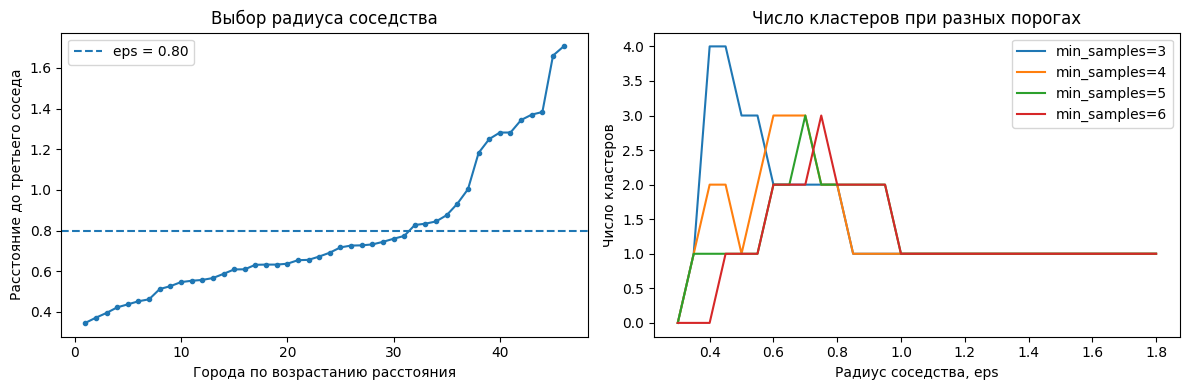

DBSCAN_RESULT: {'eps': 0.8, 'min_samples': 4, 'clusters': 2, 'noise': 8, 'coverage': np.float64(0.8260869565217391), 'silhouette_without_noise': np.float64(0.5120134885325117), 'sizes': '[19, 19]'}


,Cities,Work,Price,Salary
DBSCAN,,,,
-1,8,1900.38,99.92,61.26
1,19,1792.00,77.53,55.16
2,19,1959.21,50.12,14.79


Шум (8 городов): Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo, Zurich
Кластер 1 (19 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna
Кластер 2 (19 городов): Athens, Bogota, Bombay, Buenos Aires, Caracas, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Tel Aviv


In [ ]:
# Считаем силуэт для разбиений с несколькими группами.
def silhouette_if_defined(points, group_labels):
    count = len(set(group_labels))
    return silhouette_score(points, group_labels) if 2 <= count < len(points) else np.nan


# Сохраняем модель и показатели для каждого сочетания порогов.
db_fits = {}


def fit_dbscan(eps, min_samples):
    key = (round(float(eps), 2), int(min_samples))
    if key not in db_fits:
        model = DBSCAN(eps=key[0], min_samples=key[1]).fit(X3)
        assigned = model.labels_
        keep = assigned != -1
        counts = pd.Series(assigned[keep]).value_counts().sort_index().tolist()
        metrics = {'eps': key[0], 'min_samples': key[1],
                   'clusters': len(set(assigned[keep])), 'noise': int((~keep).sum()),
                   'coverage': keep.mean(),
                   'silhouette_without_noise': silhouette_if_defined(X3[keep], assigned[keep]),
                   'sizes': str(counts)}
        db_fits[key] = {'model': model, 'labels': assigned, 'metrics': metrics}
    return db_fits[key]


# Получаем показатели уже построенного разбиения.
def db_metrics(eps, min_samples):
    return fit_dbscan(eps, min_samples)['metrics'].copy()

# Перебираем пороги и отбираем варианты с покрытием не ниже 80%.
db_grid = pd.DataFrame([db_metrics(ep, ms) for ms in [3,4,5,6]
                        for ep in np.round(np.arange(.30,1.81,.05),2)])
valid_db = db_grid[(db_grid.clusters>=2)&(db_grid.coverage>=.8)]
display(valid_db.sort_values(['silhouette_without_noise','coverage'], ascending=False).round(4))

# Показываем расстояния до соседей и изменение числа групп.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
neigh_dist = NearestNeighbors(n_neighbors=4).fit(X3).kneighbors(X3)[0][:,-1]
axes[0].plot(np.arange(1,len(X3)+1), np.sort(neigh_dist), 'o-', markersize=3)
axes[0].axhline(.8, linestyle='--', label='eps = 0.80')
axes[0].set(title='Выбор радиуса соседства', xlabel='Города по возрастанию расстояния', ylabel='Расстояние до третьего соседа')
axes[0].legend()
for ms in [3,4,5,6]:
    part = db_grid[db_grid.min_samples.eq(ms)]
    axes[1].plot(part.eps, part.clusters, label=f'min_samples={ms}')
axes[1].set(title='Число кластеров при разных порогах', xlabel='Радиус соседства, eps', ylabel='Число кластеров')
axes[1].legend(); plt.tight_layout(); plt.show()

# Строим итоговое разбиение при выбранных порогах.
db_eps, db_min_samples = .8, 4
db_model = fit_dbscan(db_eps, db_min_samples)['model']
db_raw_labels = db_model.labels_
keep3 = db_raw_labels != -1
# Нумеруем группы по убыванию средней зарплаты.
db_labels = relabel_by_salary(cities3, db_raw_labels)
cities3['DBSCAN'] = db_labels
# Отмечаем ядровые, граничные и шумовые города.
is_core3 = np.zeros(len(X3), dtype=bool)
is_core3[db_model.core_sample_indices_] = True
cities3['Point_type'] = np.where(db_labels==-1,'noise',np.where(is_core3,'core','border'))
db_selected = db_metrics(db_eps, db_min_samples)
print('DBSCAN_RESULT:', db_selected)
# Выводим размеры, средние признаки и состав групп.
db_summary = show_cluster_summary(cities3, 'DBSCAN', features3, assignments=False)


### Выбранное решение

Выбираем **eps = 0,80, min_samples = 4**. При 46 наблюдениях это даёт **две группы по 19 городов и 8 шумовых точек**, то есть покрытие **82,61%**. У eps = 0,75 и того же min_samples силуэт немного выше, но к группам отнесён ещё на один город меньше. Выбор 0,80 сохраняет больше наблюдений при сопоставимом разделении; это компромисс, а не механическая максимизация силуэта.


,City,Work,Price,Salary,DBSCAN,Point_type
0,Geneva,1880.0,95.9,90.3,-1,noise
1,Helsinki,1667.0,113.6,66.6,-1,noise
2,Hong_Kong,2375.0,63.8,27.8,-1,noise
3,Oslo,1583.0,115.5,63.7,-1,noise
4,Stockholm,1805.0,111.3,39.2,-1,noise
5,Taipei,2145.0,84.3,34.5,-1,noise
6,Tokyo,1880.0,115.0,68.0,-1,noise
7,Zurich,1868.0,100.0,100.0,-1,noise
8,Amsterdam,1714.0,65.6,49.0,1,core
9,Brussels,1708.0,73.8,50.5,1,core


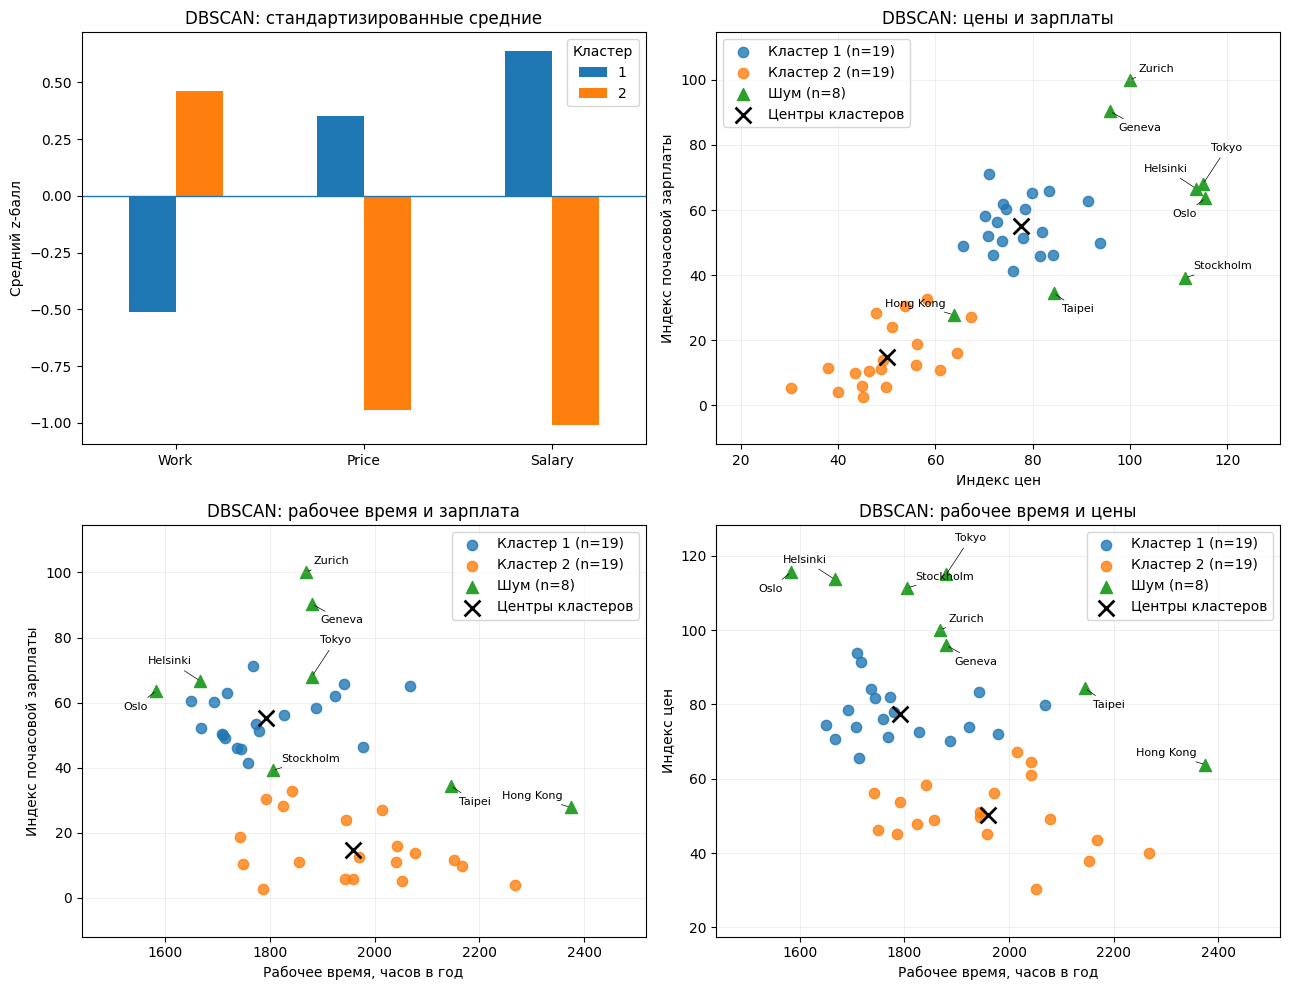

Число ядер, граничных и шумовых точек:
Point_type
core      31
noise      8
border     7


In [ ]:
# Показываем назначения городов, профили групп и парные графики.
display(cities3.sort_values(['DBSCAN', 'City']).reset_index(drop=True))
plot_cluster_profiles(cities3, X3, db_labels, features3, 'DBSCAN', annotate_noise=True)
print('Число ядер, граничных и шумовых точек:')
print(cities3.Point_type.value_counts().to_string())


### Интерпретация групп и шума

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Интерпретация |
|---|---:|---:|---:|---:|---|
| 1 | 19 | 1792,00 | 77,53 | 55,16 | Плотная группа с более высокими ценами и зарплатами и меньшим рабочим временем |
| 2 | 19 | 1959,21 | 50,12 | 14,79 | Плотная группа с более низкими ценами и зарплатами и большим рабочим временем |

В первую группу входят, например, Amsterdam, London и New York; во вторую — Athens, Bombay и Mexico City. Обе группы сохраняют основной экономический контраст из предыдущих работ.

**Шум:** Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo и Zurich. Это 8 городов, не присоединённых к плотным группам при выбранных параметрах. Они неоднородны: Geneva, Helsinki, Oslo, Stockholm, Tokyo и Zurich имеют высокие индексы цен; Hong Kong отличается большим рабочим временем, а Taipei также сочетанием рабочего времени и цен. Отсутствие собственной достаточно плотной группы нельзя трактовать как общую экономическую характеристику всех восьми городов. Средние по шуму приведены только описательно.

### Чувствительность и сравнение методов


### Почему DBSCAN объединяет эти города?

Закрашенные кружки — ядра, пустые — граничные точки, треугольники — шум. Линии показывают близость в исходном пространстве трёх стандартизированных признаков. На плоскости PCA расстояния могут искажаться: близость на рисунке сама по себе не означает наличие связи. Чёрные крестики — средние точки групп, которые не участвуют в работе DBSCAN.


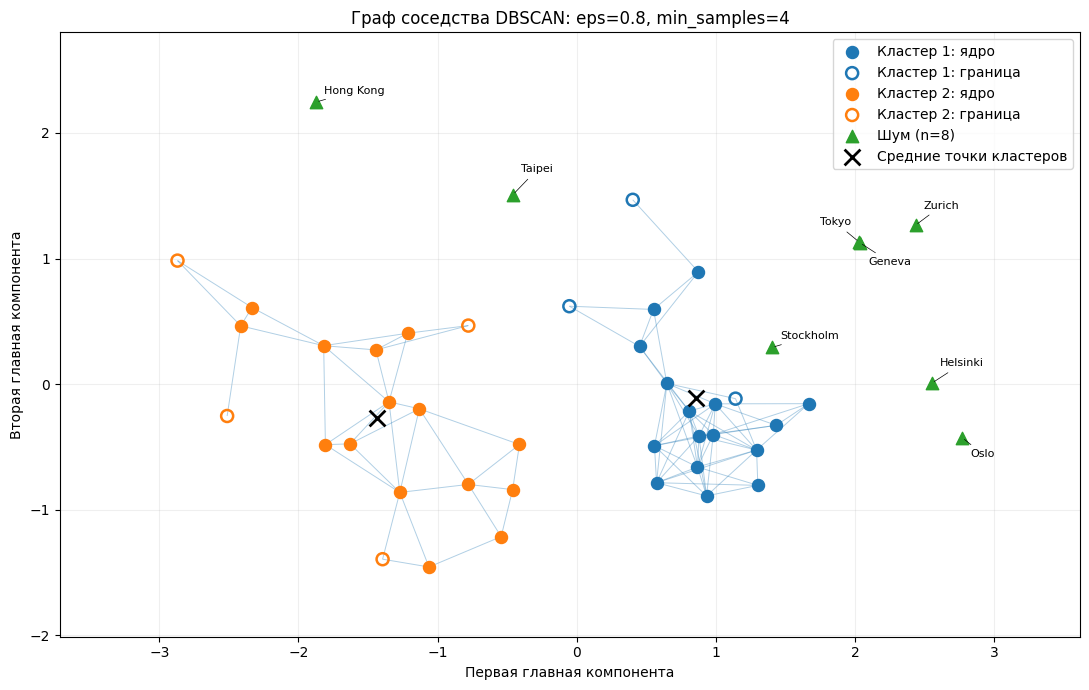

Две компоненты сохраняют 93.5% разброса. Связей на графе: 96.


In [ ]:
# Получаем координаты городов для двумерного рисунка.
graph_pca = PCA(n_components=2)
graph_xy = graph_pca.fit_transform(X3)
# Считаем расстояния между городами по трём признакам.
graph_distances = np.linalg.norm(X3[:, None, :] - X3[None, :, :], axis=2)
# Собираем связи между близкими городами одной группы с участием ядер.
graph_edges = []
for i in range(len(X3)):
    for j in range(i + 1, len(X3)):
        if (db_labels[i] != -1 and db_labels[i] == db_labels[j]
                and (is_core3[i] or is_core3[j]) and graph_distances[i, j] <= db_eps):
            graph_edges.append([graph_xy[i], graph_xy[j]])
# Рисуем связи, ядра и граничные города.
fig, ax = plt.subplots(figsize=(11, 7))
ax.add_collection(LineCollection(graph_edges, linewidths=.7, alpha=.35, zorder=1))
for cluster in sorted(set(db_labels) - {-1}):
    core_mask = (db_labels == cluster) & is_core3
    border_mask = (db_labels == cluster) & ~is_core3
    points = ax.scatter(graph_xy[core_mask, 0], graph_xy[core_mask, 1], s=75,
                        label=f'Кластер {cluster}: ядро', zorder=3)
    ax.scatter(graph_xy[border_mask, 0], graph_xy[border_mask, 1], s=75,
               facecolors='none', edgecolors=points.get_facecolor()[0], linewidths=1.8,
               label=f'Кластер {cluster}: граница', zorder=3)
# Добавляем шумовые города и их названия.
noise_indices = np.flatnonzero(db_labels == -1)
ax.scatter(graph_xy[noise_indices, 0], graph_xy[noise_indices, 1], marker='^', s=80,
           label=f'Шум (n={len(noise_indices)})', zorder=3)
noise_offsets = [(6, -16), (6, 12), (6, 6), (6, -14),
                 (6, 6), (6, 16), (-6, 12), (6, 12)]
annotate_cities(ax, cities3.loc[noise_indices, 'City'], graph_xy[noise_indices], noise_offsets)
# Отмечаем средние точки кластеров и оформляем график.
mean_points = np.array([X3[db_labels == cluster].mean(axis=0)
                        for cluster in sorted(set(db_labels) - {-1})])
mean_xy = graph_pca.transform(mean_points)
ax.scatter(mean_xy[:, 0], mean_xy[:, 1], marker='x', c='black',
           s=130, linewidths=2, label='Средние точки кластеров', zorder=4)
explained = graph_pca.explained_variance_ratio_.sum() * 100
ax.set(title=f'Граф соседства DBSCAN: eps={db_eps}, min_samples={db_min_samples}',
       xlabel='Первая главная компонента', ylabel='Вторая главная компонента')
ax.margins(.15)
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print(f'Две компоненты сохраняют {explained:.1f}% разброса. Связей на графе: {len(graph_edges)}.')


Внутри двух групп есть цепочки связей через ядра. Граничные города присоединяются к ним, а восемь шумовых не имеют связей с ядрами при выбранном радиусе. Две компоненты PCA сохраняют 93,5% разброса, но связи на графе определяются исходными тремя признаками.


## Проверка чувствительности при двух кластерах

Проверяем выбранное решение при небольшом изменении порогов. У DBSCAN число групп при этом может измениться.


In [ ]:
# Сравниваем число групп и шумовых городов при соседних порогах.
nearby3 = db_grid[db_grid.eps.between(.65,.95)]
display(nearby3.round(4))
print('Количество кластеров в окрестности параметров:')
display(nearby3.pivot(index='eps', columns='min_samples', values='clusters'))
print('Количество шумовых точек в той же окрестности:')
display(nearby3.pivot(index='eps', columns='min_samples', values='noise'))

# Получаем разбиения из первых двух лабораторных.
km3 = KMeans(n_clusters=2, n_init=50, random_state=42).fit_predict(X3)
ward3 = cut_tree(linkage(X3, method='ward'), n_clusters=2).ravel()
# Сравниваем методы на полной выборке и на общих нешумовых городах.
comparison3 = []
for name, lab in [('Ward',ward3),('K-means',km3),('DBSCAN',db_labels)]:
    full_sil = silhouette_score(X3,lab) if name!='DBSCAN' else np.nan
    common_sil = silhouette_score(X3[keep3],lab[keep3])
    comparison3.append({'Method':name,'Clusters':len(set(lab)-{-1}),
                        'Noise':int((lab==-1).sum()), 'Coverage':float((lab!=-1).mean()),
                        'Silhouette_all_46':full_sil,'Silhouette_common_38':common_sil,
                        'ARI_vs_DBSCAN_common':adjusted_rand_score(db_labels[keep3],lab[keep3])})
comparison3 = pd.DataFrame(comparison3)
display(comparison3.round(4))
# Сохраняем назначения, профили, сетку порогов и сравнение методов.
cities3.to_csv('lab3_dbscan_clusters.csv', index=False, encoding='utf-8-sig')
db_summary.to_csv('lab3_dbscan_profiles.csv', encoding='utf-8-sig')
db_grid.to_csv('lab3_dbscan_parameter_grid.csv', index=False, encoding='utf-8-sig')
comparison3.to_csv('labs_1_3_comparison.csv', index=False, encoding='utf-8-sig')


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
7,0.65,3,2,13,0.7174,0.5454,"[16, 17]"
8,0.70,3,2,11,0.7609,0.5400,"[17, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
11,0.85,3,1,8,0.8261,NaN,[38]
12,0.90,3,1,8,0.8261,NaN,[38]
13,0.95,3,1,8,0.8261,NaN,[38]
38,0.65,4,3,15,0.6739,0.3793,"[16, 4, 11]"
39,0.70,4,3,11,0.7609,0.3565,"[17, 4, 14]"
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"


Количество кластеров в окрестности параметров:


min_samples,3,4,5,6
eps,,,,
0.65,2,3,2,2
0.70,2,3,3,2
0.75,2,2,2,3
0.80,2,2,2,2
0.85,1,1,2,2
0.90,1,1,2,2
0.95,1,1,2,2


Количество шумовых точек в той же окрестности:


min_samples,3,4,5,6
eps,,,,
0.65,13,15,25,27
0.70,11,11,21,24
0.75,8,9,9,16
0.80,8,8,9,12
0.85,8,8,9,11
0.90,8,8,8,9
0.95,8,8,8,9


,Method,Clusters,Noise,Coverage,Silhouette_all_46,Silhouette_common_38,ARI_vs_DBSCAN_common
0,Ward,2,0,1.0000,0.4705,0.512,1.0
1,K-means,2,0,1.0000,0.4705,0.512,1.0
2,DBSCAN,2,8,0.8261,NaN,0.512,1.0


### Вывод по DBSCAN и сравнение трёх работ

При **eps = 0,80, min_samples = 4** DBSCAN выделил **2 кластера по 19 городов** и **8 шумовых наблюдений**. Силуэт без шума — **0,5120**, покрытие — **82,61%**. Группы интерпретируются как два различных сочетания цен, почасовых зарплат и рабочего времени. Шумовые города перечислены и разобраны отдельно.

**Чувствительность существенна:** при min_samples = 4 и eps = 0,75 ещё сохраняются две группы (9 шумовых точек), но при eps = 0,85 группы уже сливаются в одну (8 шумовых точек). Следовательно, результат не следует представлять как единственное устойчивое число естественных групп; он зависит от принятого масштаба плотности.

| Метод | Группы | Шум | Покрытие 46 городов | Силуэт на всех 46 | Силуэт на общих 38 |
|---|---:|---:|---:|---:|---:|
| Ward | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| k-means | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| DBSCAN | 2: 19 и 19 | 8 | 82,61% | не рассчитывается | 0,5120 |

На общей подвыборке 38 городов **все три разбиения совпадают (ARI = 1)**. Более высокий силуэт DBSCAN по сравнению с 0,4705 объясняется в данном сравнении выбором подмножества объектов, поэтому не доказывает превосходство DBSCAN. Для общей сегментации всех полных наблюдений Ward и k-means удобнее; DBSCAN дополнительно показывает города, не включённые в плотные группы при выбранных параметрах.


## Сравнение со сторонними показателями

Показатели за **1991 год**: ИЧР — от 0 до 1; ожидаемая продолжительность жизни при рождении — в годах, для обоих полов.
Источники: [ПРООН, исторический ряд ИЧР](https://hdr.undp.org/sites/default/files/2025_HDR/HDR25_Composite_indices_complete_time_series.csv) и [Всемирный банк, продолжительность жизни](https://data.worldbank.org/indicator/SP.DYN.LE00.IN).
Для Тайваня в этих источниках нет значений: Тайбэй сохраняется в исходной кластеризации, но пропускается во внешней оценке.

Кластеризация по-прежнему использует **только Work, Price и Salary**. Здесь проверяем, отличаются ли полученные группы по сторонним показателям.
В таблице средние и медианы рассчитаны по городам. Показатель **η²** показывает долю разброса стороннего признака, которая приходится на различия между средними групп: от 0 до 1, выше — сильнее разделение по этому признаку.
Дополнительно считаем η² с равным суммарным весом стран, чтобы несколько городов одной страны не усиливали её вклад.

Это описательная проверка соответствия, а не доказательство причинной связи. Национальные значения повторяются у городов одной страны; одна страна может встречаться в нескольких кластерах. Продолжительность жизни уже входит в ИЧР, поэтому эти две оценки взаимосвязаны. Рост η² при увеличении числа групп сам по себе не доказывает улучшение кластеризации.

В DBSCAN шум — отдельный статус, а не кластер: показываем его на графиках, но не включаем в η². При сравнении порогов учитываем изменение числа исключённых городов.


Города без полного набора сторонних показателей:


,City,Country,HDI,Life_expectancy
40,Taipei,Тайвань,NaN,NaN


Основное разбиение
Городов с двумя показателями: 45/46; в кластерах: 38; шум с показателями: 7


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,7,6,0.836,0.857,0.764,0.863,77.402,77.515,75.228,79.037
Кластер 1,19,14,0.839,0.841,0.774,0.878,76.102,75.617,75.025,77.593
Кластер 2,19,18,0.658,0.669,0.383,0.826,68.320,71.172,45.483,77.137


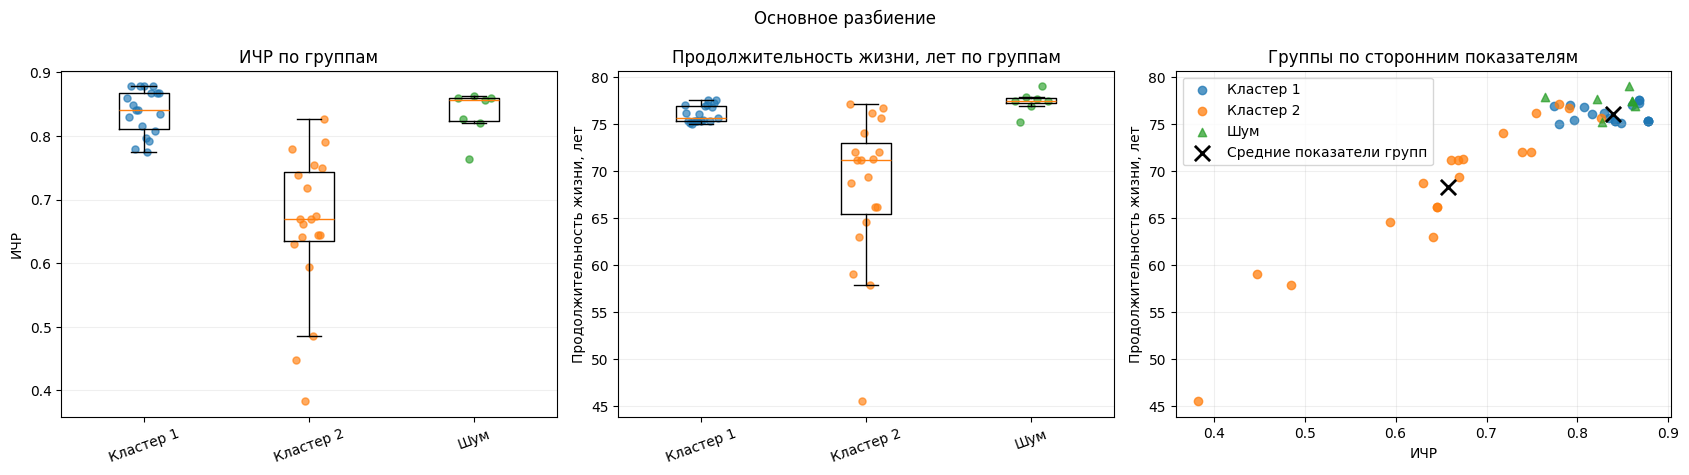

,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
0,38,32,0.5376,0.4652,0.3361,0.2968


In [ ]:
# Сравниваем готовые группы по национальным показателям.
external_missing = attach_country_indicators(cities3)
print('Города без полного набора сторонних показателей:')
display(external_missing.loc[external_missing[external_features].isna().any(axis=1)])
external_main_result = compare_living_standards(cities3, db_labels, 'Основное разбиение')
display(pd.DataFrame([external_main_result]).round(4))


### Что показывает сравнение

У двух кластеров DBSCAN средний ИЧР — **0,839 против 0,658**, а продолжительность жизни — **76,1 против 68,3 года**. η² без шума составляет **0,538 и 0,336**, при равном суммарном весе стран — **0,465 и 0,297**. Основной контраст уровня жизни виден, но группы перекрываются.

В оценке кластеров участвуют **38 городов из 32 стран и территорий**. Из восьми шумовых городов показатели известны для семи: их средний ИЧР — **0,836**, продолжительность жизни — **77,4 года**. Шум здесь не означает низкий уровень жизни: эти города не вошли в достаточно плотные группы по исходным Work, Price и Salary.

Напрямую сопоставлять η² DBSCAN с Ward и k-means на всех городах нельзя: DBSCAN исключает шум и оценивается на другом наборе наблюдений.


## Что если выбрать другие пороги

Изменим eps и min_samples. Проверим, улучшается ли разделение и сколько городов при этом остаётся вне кластеров.


Исходный вариант: eps=0.80, min_samples=4. Силуэт считается без шума.


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
0,0.80,4,2,8,0.8261,0.5120,"[19, 19]"
1,0.65,4,3,15,0.6739,0.3793,"[16, 4, 11]"
2,0.75,4,2,9,0.8043,0.5234,"[18, 19]"
3,0.85,4,1,8,0.8261,NaN,[38]
4,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
5,0.80,5,2,9,0.8043,0.5234,"[18, 19]"
6,0.80,6,2,12,0.7391,0.5393,"[18, 16]"
7,0.65,6,2,27,0.4130,0.7216,"[13, 6]"
8,0.95,5,2,8,0.8261,0.5120,"[19, 19]"


Сравнение на одних и тех же городах:


,eps,min_samples,Общих городов,Силуэт исходного на общих,Силуэт нового на общих,ARI на общих
0,0.80,4,38,0.5120,0.5120,1.0000
1,0.65,4,31,0.5542,0.3793,0.8094
2,0.75,4,37,0.5234,0.5234,1.0000
3,0.85,4,38,0.5120,NaN,0.0000
4,0.80,3,38,0.5120,0.5120,1.0000
5,0.80,5,37,0.5234,0.5234,1.0000
6,0.80,6,34,0.5393,0.5393,1.0000
7,0.65,6,19,0.7216,0.7216,1.0000
8,0.95,5,38,0.5120,0.5120,1.0000


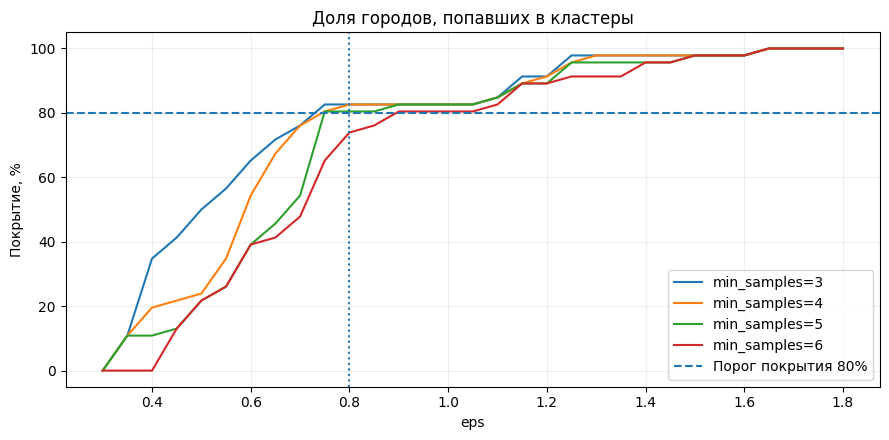

eps=0.75, min_samples=4: дополнительно стали шумом — Los Angeles
eps=0.80, min_samples=6: дополнительно стали шумом — Bombay, Los Angeles, Manila, Tel Aviv
eps=0.65, min_samples=6: дополнительно стали шумом — Athens, Bogota, Bombay, Chicago, Houston, Kuala Lumpur, Lagos, Lisbon, Los Angeles, Luxembourg, Manila, New York, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Tel Aviv, Toronto


In [ ]:
# Проверяем альтернативные сочетания порогов.
threshold_cases = [(.80, 4), (.65, 4), (.75, 4), (.85, 4),
                   (.80, 3), (.80, 5), (.80, 6), (.65, 6), (.95, 5)]
threshold_rows, common_rows = [], []
for eps, min_samples in threshold_cases:
    alternative = fit_dbscan(eps, min_samples)['labels']
    threshold_rows.append(db_metrics(eps, min_samples))
    # Сравниваем разбиения на городах, вошедших в группы в обоих вариантах.
    common_mask = (db_labels != -1) & (alternative != -1)
    base_common = db_labels[common_mask]
    alternative_common = alternative[common_mask]
    n_common = int(common_mask.sum())
    common_rows.append({
        'eps': eps, 'min_samples': min_samples, 'Общих городов': n_common,
        'Силуэт исходного на общих': silhouette_if_defined(X3[common_mask], base_common),
        'Силуэт нового на общих': silhouette_if_defined(X3[common_mask], alternative_common),
        'ARI на общих': adjusted_rand_score(base_common, alternative_common) if n_common else np.nan})

# Выводим показатели альтернативных разбиений.
threshold_results = pd.DataFrame(threshold_rows)
threshold_common = pd.DataFrame(common_rows)
print('Исходный вариант: eps=0.80, min_samples=4. Силуэт считается без шума.')
display(threshold_results.round(4))
print('Сравнение на одних и тех же городах:')
display(threshold_common.round(4))

# Сравниваем долю городов в кластерах при смене порогов.
fig, ax = plt.subplots(figsize=(9, 4.5))
for min_samples in [3, 4, 5, 6]:
    part = db_grid[db_grid.min_samples.eq(min_samples)]
    ax.plot(part.eps, part.coverage * 100, label=f'min_samples={min_samples}')
ax.set(title='Доля городов, попавших в кластеры', xlabel='eps', ylabel='Покрытие, %')
ax.axhline(80, linestyle='--', label='Порог покрытия 80%')
ax.axvline(db_eps, linestyle=':')
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

# Перечисляем города, дополнительно ставшие шумом.
for eps, min_samples in [(.75, 4), (.80, 6), (.65, 6)]:
    alternative = fit_dbscan(eps, min_samples)['labels']
    new_noise = cities3.loc[(alternative == -1) & (db_labels != -1), 'City']
    print(f'eps={eps:.2f}, min_samples={min_samples}: дополнительно стали шумом —',
          ', '.join(new_noise.str.replace('_', ' ')))
# Сохраняем результаты экспериментов с порогами.
threshold_results.to_csv('lab3_alternative_thresholds.csv', index=False, encoding='utf-8-sig')
threshold_common.to_csv('lab3_alternative_thresholds_common.csv', index=False, encoding='utf-8-sig')


### Стало ли лучше?

* Если немного уменьшить eps до 0,75, силуэт чуть растёт, но Лос-Анджелес дополнительно становится шумом. При eps=0,80 и min_samples=5 получается то же разбиение на 37 городах.

* Если повысить min_samples до 6 при eps=0,80, шумовых городов становится 12. Если одновременно уменьшить eps до 0,65, силуэт растёт до 0,7216, но в группах остаётся всего 19 из 46 городов — около 41%. Большая часть данных исключена из кластеров.

* Если увеличить eps до 0,85 при min_samples=4, две группы соединяются в одну. Если уменьшить eps до 0,65 при min_samples=4, появляются три группы, но шумовых городов уже 15, а силуэт падает до 0,3793.

* При eps=0,80, min_samples=3 и при eps=0,95, min_samples=5 получаем тот же результат, что и в исходном варианте: две группы по 19 городов и 8 шумовых.

Явного улучшения для задачи выделения нескольких групп с покрытием хотя бы 80% не получилось. Исходные пороги 0,80 и 4 остаются разумным компромиссом. Вариант 0,75 и 4 тоже допустимт.


### Сторонние показатели при других порогах

Проверим, как при изменении порогов меняется разделение по ИЧР и продолжительности жизни. Шум показываем отдельно и исключаем из η². Для прямого сравнения дополнительно считаем η² на одних и тех же городах, вошедших в кластеры во всех выбранных вариантах. Национальные показатели не участвуют в построении групп.


eps=0.80, min_samples=4
Городов с двумя показателями: 45/46; в кластерах: 38; шум с показателями: 7


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,7,6,0.836,0.857,0.764,0.863,77.402,77.515,75.228,79.037
Кластер 1,19,14,0.839,0.841,0.774,0.878,76.102,75.617,75.025,77.593
Кластер 2,19,18,0.658,0.669,0.383,0.826,68.320,71.172,45.483,77.137


eps=0.65, min_samples=4
Городов с двумя показателями: 45/46; в кластерах: 31; шум с показателями: 14


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,14,12,0.767,0.824,0.448,0.878,73.690,75.415,59.032,79.037
Кластер 1,16,13,0.836,0.841,0.774,0.878,76.234,76.138,75.025,77.593
Кластер 2,4,4,0.750,0.752,0.718,0.780,74.861,75.130,72.046,77.137
Кластер 3,11,10,0.652,0.669,0.383,0.826,66.818,69.368,45.483,76.759


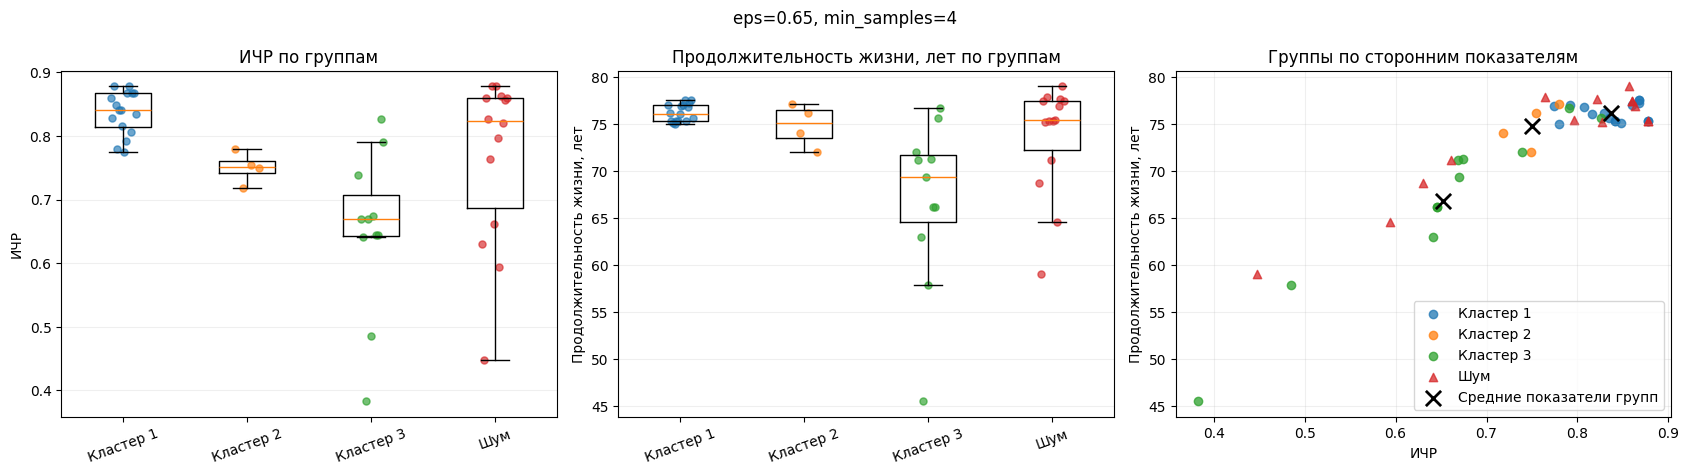

eps=0.75, min_samples=4
Городов с двумя показателями: 45/46; в кластерах: 37; шум с показателями: 8


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,8,7,0.841,0.858,0.764,0.878,77.147,77.515,75.228,79.037
Кластер 1,18,14,0.836,0.841,0.774,0.878,76.143,75.850,75.025,77.593
Кластер 2,19,18,0.658,0.669,0.383,0.826,68.320,71.172,45.483,77.137


eps=0.85, min_samples=4
Городов с двумя показателями: 45/46; в кластерах: 38; шум с показателями: 7


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,7,6,0.836,0.857,0.764,0.863,77.402,77.515,75.228,79.037
Кластер 1,38,32,0.748,0.786,0.383,0.878,72.211,75.343,45.483,77.593


eps=0.80, min_samples=6
Городов с двумя показателями: 45/46; в кластерах: 34; шум с показателями: 11


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,11,10,0.778,0.827,0.448,0.878,74.327,76.981,59.032,79.037
Кластер 1,18,14,0.836,0.841,0.774,0.878,76.143,75.850,75.025,77.593
Кластер 2,16,15,0.667,0.670,0.383,0.826,68.604,71.196,45.483,77.137


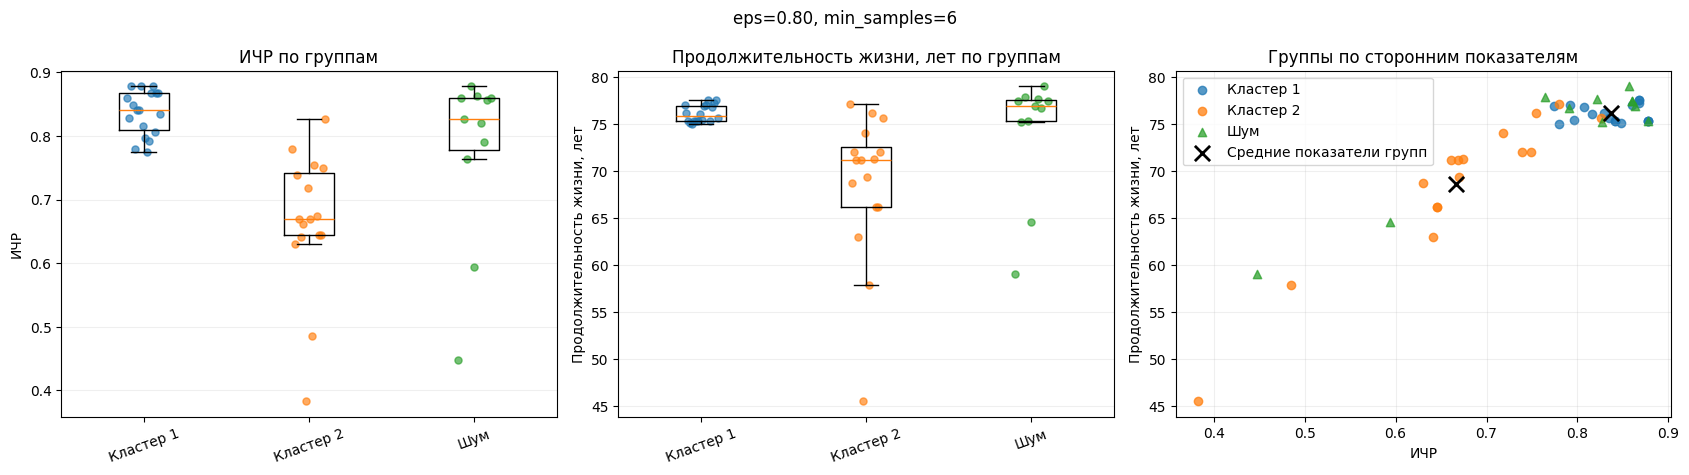

eps=0.65, min_samples=6
Городов с двумя показателями: 45/46; в кластерах: 19; шум с показателями: 26


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,26,21,0.750,0.786,0.383,0.878,72.515,75.366,45.483,79.037
Кластер 1,13,12,0.828,0.835,0.774,0.868,76.263,76.192,75.025,77.593
Кластер 2,6,6,0.672,0.670,0.485,0.826,68.169,70.270,57.826,75.646


eps=0.95, min_samples=5
Городов с двумя показателями: 45/46; в кластерах: 38; шум с показателями: 7


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Шум,7,6,0.836,0.857,0.764,0.863,77.402,77.515,75.228,79.037
Кластер 1,19,14,0.839,0.841,0.774,0.878,76.102,75.617,75.025,77.593
Кластер 2,19,18,0.658,0.669,0.383,0.826,68.320,71.172,45.483,77.137


,eps,min_samples,Шумовых городов,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
0,0.80,4,8,38,32,0.5376,0.4652,0.3361,0.2968
1,0.65,4,15,31,27,0.5558,0.5063,0.4192,0.3874
2,0.75,4,9,37,32,0.5263,0.4652,0.3325,0.2968
3,0.85,4,8,38,32,NaN,NaN,NaN,NaN
4,0.80,6,12,34,29,0.5520,0.4904,0.3332,0.2963
5,0.65,6,27,19,18,0.5670,0.5577,0.5447,0.5441
6,0.95,5,8,38,32,0.5376,0.4652,0.3361,0.2968


Общие города: eps=0.80, min_samples=4
Городов с двумя показателями: 19/19; в кластерах: 19; шум с показателями: 0


... (10 outputs left out)

,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,13,12,0.828,0.835,0.774,0.868,76.263,76.192,75.025,77.593
Кластер 2,6,6,0.672,0.670,0.485,0.826,68.169,70.270,57.826,75.646


Общие города: eps=0.95, min_samples=5
Городов с двумя показателями: 19/19; в кластерах: 19; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,13,12,0.828,0.835,0.774,0.868,76.263,76.192,75.025,77.593
Кластер 2,6,6,0.672,0.670,0.485,0.826,68.169,70.270,57.826,75.646


,eps,min_samples,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
0,0.80,4,19,18,0.567,0.5577,0.5447,0.5441
1,0.65,4,19,18,0.567,0.5577,0.5447,0.5441
2,0.75,4,19,18,0.567,0.5577,0.5447,0.5441
3,0.85,4,19,18,NaN,NaN,NaN,NaN
4,0.80,6,19,18,0.567,0.5577,0.5447,0.5441
5,0.65,6,19,18,0.567,0.5577,0.5447,0.5441
6,0.95,5,19,18,0.567,0.5577,0.5447,0.5441


In [ ]:
# Сравниваем сторонние показатели при разных порогах.
external_threshold_cases = [(.80, 4), (.65, 4), (.75, 4), (.85, 4),
                            (.80, 6), (.65, 6), (.95, 5)]
external_threshold_labels = {
    (eps, ms): fit_dbscan(eps, ms)['labels']
    for eps, ms in external_threshold_cases}
external_threshold_rows = []
for (eps, ms), assigned in external_threshold_labels.items():
    named_labels = relabel_by_salary(cities3, assigned)
    external_result = compare_living_standards(
        cities3, named_labels, f'eps={eps:.2f}, min_samples={ms}',
        plots=(eps, ms) in [(.65, 4), (.80, 6)])
    external_threshold_rows.append({'eps': eps, 'min_samples': ms,
                                    'Шумовых городов': int((assigned == -1).sum()),
                                    **external_result})
display(pd.DataFrame(external_threshold_rows).round(4))

# Повторяем оценку на одинаковом наборе городов.
external_common_mask = np.logical_and.reduce([
    assigned != -1 for assigned in external_threshold_labels.values()])
external_common_rows = []
for (eps, ms), assigned in external_threshold_labels.items():
    external_result = compare_living_standards(
        cities3.loc[external_common_mask], assigned[external_common_mask] + 1,
        f'Общие города: eps={eps:.2f}, min_samples={ms}', plots=False)
    external_common_rows.append({'eps': eps, 'min_samples': ms, **external_result})
display(pd.DataFrame(external_common_rows).round(4))


### Вывод по сторонним показателям

При **eps=0,65, min_samples=4** три группы имеют средний ИЧР **0,836; 0,750; 0,652** и продолжительность жизни **76,2; 74,9; 66,8 года**. На оставшихся 31 городе разделение по продолжительности жизни выражено сильнее, но шумом становятся 15 городов из 46.

При **eps=0,65, min_samples=6** η² возрастает до **0,567 по ИЧР и 0,545 по продолжительности жизни**, однако в группах остаётся только **19 из 46 городов**. На этих же 19 городах исходный вариант даёт те же оценки: рост связан с отбором наблюдений, а не с новым разделением этих городов.

На общем наборе из 19 городов все рассмотренные варианты с двумя и более кластерами дают одинаковые группы и η². При **eps=0,85, min_samples=4** они сливаются в одну группу; η² для сравнения групп не рассчитывается. При **eps=0,95, min_samples=5** результат совпадает с исходным. Явного общего улучшения по сторонним показателям без потери покрытия не обнаружено.
